<a href="https://colab.research.google.com/github/Pranitha2006-collab/LibraryManagementSystem/blob/main/Personalized_Recommondation_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Archive:  /content/ml-latest-small.zip
  inflating: /content/ml-latest-small/links.csv  
  inflating: /content/ml-latest-small/tags.csv  
  inflating: /content/ml-latest-small/ratings.csv  
  inflating: /content/ml-latest-small/README.txt  
  inflating: /content/ml-latest-small/movies.csv  
Setup complete. Files in /content/ml-latest-small/
total 3244
drwxr-xr-x 2 root root    4096 Oct 17 01:07 .
drwxr-xr-x 1 root root    4096 Oct 17 01:02 ..
-rw-r--r-- 1 root root  197979 Sep 26  2018 links.csv
-rw-r--r-- 1 root root  494431 Sep 26  2018 movies.csv
-rw-r--r-- 1 root root 2483723 Sep 26  2018 ratings.csv
-rw-r--r-- 1 root root    8342 Sep 26  2018 README.txt
-rw-r--r-- 1 root root  118660 Sep 26  2018 tags.csv
Ratings: (100836, 4)
   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224
3       1       47     5.0  964983815
4       1       50     5.0  964982931

Movies: (9742, 3)
   movieId  

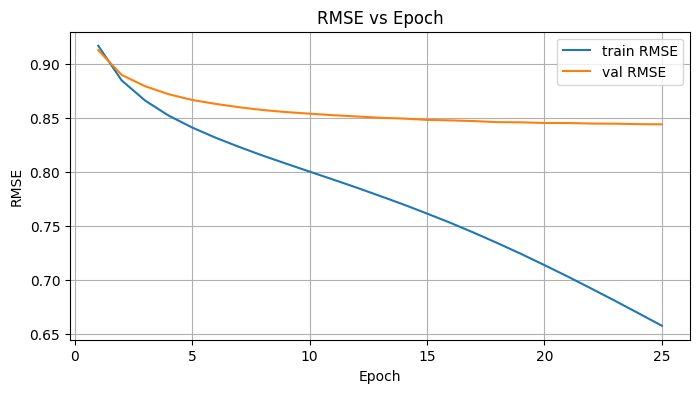

Top-10 recommendations for user index 0:
1. Godfather: Part II, The (1974) (movieId=1221, idx=1032)
2. Godfather, The (1972) (movieId=858, idx=923)
3. Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964) (movieId=750, idx=652)
4. Dark Knight, The (2008) (movieId=58559, idx=233)
5. Rear Window (1954) (movieId=904, idx=312)
6. Kill Bill: Vol. 2 (2004) (movieId=7438, idx=943)
7. Unforgiven (1992) (movieId=1266, idx=334)
8. On the Waterfront (1954) (movieId=1945, idx=2008)
9. Conversation, The (1974) (movieId=3730, idx=2295)
10. Lawrence of Arabia (1962) (movieId=1204, idx=2003)


/tmp/ipykernel_3935/2796965352.py:285: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="rating", data=ratings, palette="Blues")
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


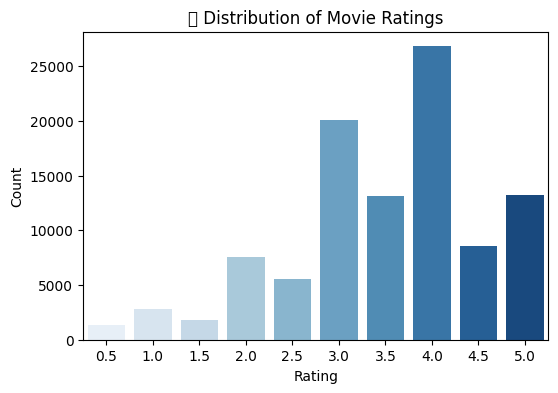

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127916 (\N{CLAPPER BOARD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


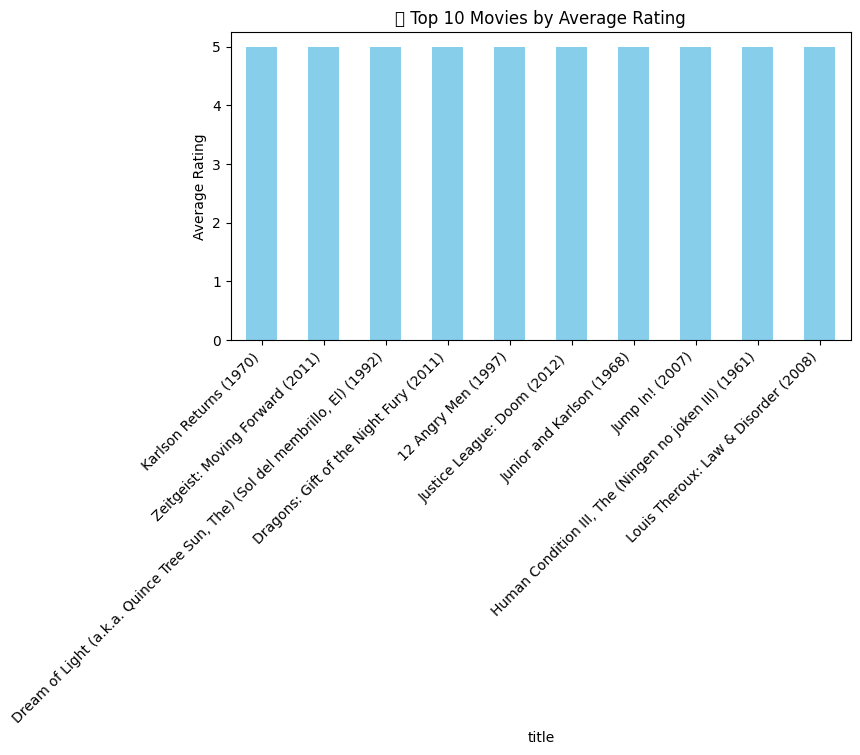

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128101 (\N{BUSTS IN SILHOUETTE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


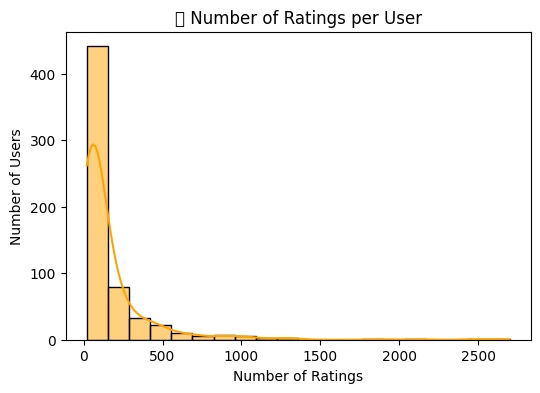

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


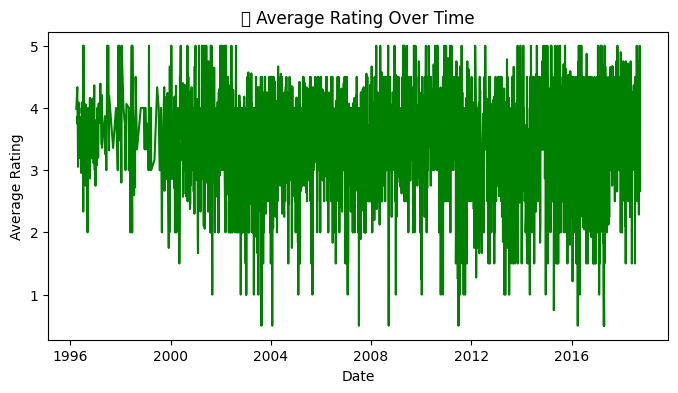

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127917 (\N{PERFORMING ARTS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


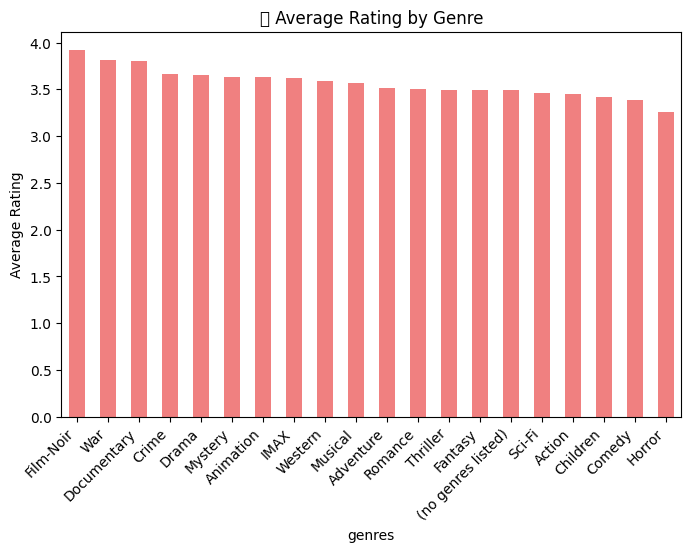

In [2]:
# === Cell 1: Setup — download MovieLens (ml-latest-small) and imports ===
!wget -q https://files.grouplens.org/datasets/movielens/ml-latest-small.zip -O /content/ml-latest-small.zip
!unzip -o /content/ml-latest-small.zip -d /content

import time
import math
import random
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
from collections import defaultdict
print("Setup complete. Files in /content/ml-latest-small/")
!ls -la /content/ml-latest-small | sed -n '1,200p'
# === Cell 2: Load and inspect data ===
ratings = pd.read_csv('/content/ml-latest-small/ratings.csv')  # userId,movieId,rating,timestamp
movies  = pd.read_csv('/content/ml-latest-small/movies.csv')   # movieId,title,genres

print("Ratings:", ratings.shape)
print(ratings.head())
print("\nMovies:", movies.shape)
print(movies.head())
# === Cell 3: Preprocessing — map ids to indices, optional filtering ===
def prepare_interaction_df(ratings_df, min_user_ratings=5, min_item_ratings=5):
    # keep only users/items with at least min interactions (optional)
    user_counts = ratings_df['userId'].value_counts()
    item_counts = ratings_df['movieId'].value_counts()
    keep_users = user_counts[user_counts >= min_user_ratings].index
    keep_items = item_counts[item_counts >= min_item_ratings].index
    df = ratings_df[ratings_df['userId'].isin(keep_users) & ratings_df['movieId'].isin(keep_items)].copy()
    # map ids to zero-based indices
    user_map = {old: new for new, old in enumerate(df['userId'].unique())}
    item_map = {old: new for new, old in enumerate(df['movieId'].unique())}
    df['u_idx'] = df['userId'].map(user_map)
    df['i_idx'] = df['movieId'].map(item_map)
    return df.reset_index(drop=True), user_map, item_map

ratings_filtered, user_map, item_map = prepare_interaction_df(ratings, min_user_ratings=5, min_item_ratings=5)
print("Filtered ratings shape:", ratings_filtered.shape)
print("Users:", ratings_filtered['u_idx'].nunique(), "Items:", ratings_filtered['i_idx'].nunique())
ratings_filtered.head()
# === Cell 4: Train/Val/Test split (time-agnostic random split) ===
def train_val_test_split(df, test_size=0.1, val_size=0.1, random_state=42):
    train_val, test = train_test_split(df, test_size=test_size, random_state=random_state)
    train, val = train_test_split(train_val, test_size=val_size/(1-test_size), random_state=random_state)
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)

train_df, val_df, test_df = train_val_test_split(ratings_filtered, test_size=0.1, val_size=0.1)
n_users = ratings_filtered['u_idx'].nunique()
n_items = ratings_filtered['i_idx'].nunique()
print("Train:", train_df.shape, "Val:", val_df.shape, "Test:", test_df.shape)
print("n_users:", n_users, "n_items:", n_items)

# === Cell 5: Baseline — Item-Item CF using cosine similarity (predict by weighted avg) ===
# Build item-user rating matrix (dense-ish for this dataset)
def build_item_user_matrix(df, n_users, n_items):
    mat = np.zeros((n_items, n_users), dtype=np.float32)
    # The original code had incorrect indentation and potentially redundant initializations.
    # This version correctly populates the rating matrix based on the dataframe.
    # The 'counts' array is returned but not used in the provided baseline evaluation, so it's kept consistent with the signature.
    counts = np.zeros((n_items, n_users), dtype=np.float32)
    for r in df.itertuples():
        mat[r.i_idx, r.u_idx] = r.rating
        counts[r.i_idx, r.u_idx] = 1.0
    return mat, counts

item_user_mat, _ = build_item_user_matrix(train_df, n_users, n_items)
print("item_user_mat shape:", item_user_mat.shape)

# Compute cosine similarity between items
print("Computing item-item cosine similarity (this may take a few seconds)...")
item_sim = cosine_similarity(item_user_mat)
np.fill_diagonal(item_sim, 0.0)  # ignore self-similarity in predictions

def item_item_predict(user_idx, item_idx, k=20):
    # weighted average of user's ratings on top-k similar items
    sims = item_sim[item_idx]  # similarity of target item to all items
    user_ratings = item_user_mat[:, user_idx]
    # select items the user rated
    rated_mask = user_ratings > 0
    if rated_mask.sum() == 0:
        return train_df['rating'].mean()
    candidate_idxs = np.where(rated_mask)[0]
    sims_candidates = sims[candidate_idxs]
    if len(sims_candidates)==0:
        return train_df['rating'].mean()
    top_k_idx = candidate_idxs[np.argsort(-sims_candidates)][:k]
    top_sims = sims[top_k_idx]
    top_ratings = user_ratings[top_k_idx]
    if top_sims.sum() == 0:
        return top_ratings.mean()
    return (top_sims.dot(top_ratings)) / (top_sims.sum())

def evaluate_baseline_rmse(test_df):
    preds = []
    for r in test_df.itertuples():
        preds.append(item_item_predict(int(r.u_idx), int(r.i_idx), k=20))
    mse = np.mean((test_df['rating'].values - np.array(preds))**2)
    return math.sqrt(mse)

t0 = time.time()
baseline_rmse = evaluate_baseline_rmse(test_df)
t1 = time.time()
print(f"Item-Item baseline RMSE: {baseline_rmse:.4f}  (eval time {t1-t0:.2f}s)")
# === Cell 6: Matrix Factorization with biases (SGD) implementation ===
class MF_Bias_SGD:
    def __init__(self, n_users, n_items, n_factors=50, lr=0.005, reg=0.02, n_epochs=25, verbose=True):
        self.n_users = n_users
        self.n_items = n_items
        self.n_factors = n_factors
        self.lr = lr
        self.reg = reg
        self.n_epochs = n_epochs
        self.verbose = verbose

    def fit(self, train_df, val_df=None):
        # Initialize
        self.mu = train_df['rating'].mean()
        self.b_u = np.zeros(self.n_users, dtype=np.float32)
        self.b_i = np.zeros(self.n_items, dtype=np.float32)
        rng = np.random.RandomState(42)
        self.p = rng.normal(scale=0.1, size=(self.n_users, self.n_factors)).astype(np.float32)
        self.q = rng.normal(scale=0.1, size=(self.n_items, self.n_factors)).astype(np.float32)

        samples = list(zip(train_df['u_idx'], train_df['i_idx'], train_df['rating']))
        best_val_rmse = float('inf')
        best_state = None
        train_rmse_history = []
        val_rmse_history = []

        for epoch in range(1, self.n_epochs + 1):
            random.shuffle(samples)
            self._sgd_epoch(samples)
            train_rmse = self.evaluate_rmse(train_df)
            val_rmse = self.evaluate_rmse(val_df) if val_df is not None and len(val_df)>0 else None
            train_rmse_history.append(train_rmse)
            val_rmse_history.append(val_rmse)
            if self.verbose:
                msg = f"Epoch {epoch}/{self.n_epochs} - train RMSE: {train_rmse:.4f}"
                if val_rmse is not None:
                    msg += f", val RMSE: {val_rmse:.4f}"
                print(msg)
                if val_rmse is not None and val_rmse < best_val_rmse:
                    best_val_rmse = val_rmse
                    best_state = (self.p.copy(), self.q.copy(), self.b_u.copy(), self.b_i.copy(), self.mu)

        # restore best if available
        if best_state is not None:
            self.p, self.q, self.b_u, self.b_i, self.mu = best_state
        return train_rmse_history, val_rmse_history

    def _sgd_epoch(self, samples):
        for (u, i, r) in samples:
            pred = self.predict_single(u, i)
            e = r - pred
            # update biases
            self.b_u[u] += self.lr * (e - self.reg * self.b_u[u])
            self.b_i[i] += self.lr * (e - self.reg * self.b_i[i])
            # update latent factors
            p_u = self.p[u].copy()
            q_i = self.q[i].copy()
            self.p[u] += self.lr * (e * q_i - self.reg * p_u)
            self.q[i] += self.lr * (e * p_u - self.reg * q_i)

    def predict_single(self, u, i):
        return self.mu + self.b_u[u] + self.b_i[i] + np.dot(self.p[u], self.q[i])

    def predict_for_user(self, u, item_indices):
        # vectorized
        return (self.mu + self.b_u[u] + self.b_i[item_indices] + self.p[u].dot(self.q[item_indices].T))

    def evaluate_rmse(self, df):
        if df is None or len(df)==0:
            return None
        preds = df.apply(lambda row: self.predict_single(int(row['u_idx']), int(row['i_idx'])), axis=1)
        mse = np.mean((df['rating'] - preds) ** 2)
        return math.sqrt(mse)

    def recommend_top_k(self, u, k=10, known_item_set=None):
        all_items = np.arange(self.n_items)
        scores = self.predict_for_user(u, all_items)
        if known_item_set:
            mask = np.ones(len(scores), dtype=bool)
            mask[list(known_item_set)] = False
            scores = scores[mask]
            items = all_items[mask]
        else:
            items = all_items
        top_idx = np.argpartition(-scores, k)[:k]
        top_items = items[top_idx[np.argsort(-scores[top_idx])]]
        return list(top_items)
# === Cell 7: Train MF model (adjust hyperparams here) ===
mf = MF_Bias_SGD(n_users=n_users, n_items=n_items, n_factors=50, lr=0.005, reg=0.02, n_epochs=25, verbose=True)

t0 = time.time()
train_hist, val_hist = mf.fit(train_df, val_df=val_df)
t1 = time.time()
print(f"Training finished in {t1-t0:.1f}s")

test_rmse = mf.evaluate_rmse(test_df)
print(f"Matrix Factorization test RMSE: {test_rmse:.4f}")
# === Cell 8: Compare baseline vs MF and show RMSEs + plot training curves ===
print(f"Item-Item baseline RMSE: {baseline_rmse:.4f}")
print(f"MF test RMSE: {test_rmse:.4f}")

# Plot RMSE over epochs (train/val)
plt.figure(figsize=(8,4))
epochs = list(range(1, len(train_hist)+1))
plt.plot(epochs, train_hist, label='train RMSE')
if any(v is not None for v in val_hist):
    plt.plot(epochs, val_hist, label='val RMSE')
    plt.xlabel("Epoch")
    plt.ylabel("RMSE")
    plt.title("RMSE vs Epoch")
    plt.legend()
    plt.grid(True)
    plt.show()
# === Cell 9: Demo — show top-10 recommendations for a sample user (original movie titles) ===
# Build inverse maps for movieId titles
inv_item_map = {v:k for k,v in item_map.items()}  # index -> original movieId
movie_titles = movies.set_index('movieId')['title'].to_dict()

sample_user_idx = 0  # change to any user index (< n_users)
# get known items from training data
known_items = set(train_df[train_df['u_idx'] == sample_user_idx]['i_idx'].tolist())
top_items_idx = mf.recommend_top_k(sample_user_idx, k=10, known_item_set=known_items)

print(f"Top-10 recommendations for user index {sample_user_idx}:")
for rank, idx in enumerate(top_items_idx, start=1):
    movieId = inv_item_map[idx]
    title = movie_titles.get(movieId, f"movie_{movieId}")
    print(f"{rank}. {title} (movieId={movieId}, idx={idx})")

# === Cell 10: Quick hyperparameter sweep (lightweight) ===
# Warning: this is a small sweep; enlarge ranges as needed but will take longer.
def quick_sweep(train_df, val_df, n_users, n_items):
    grid = [
        {'n_factors': 20, 'lr': 0.007, 'reg': 0.02},
        {'n_factors': 50, 'lr': 0.005, 'reg': 0.02},
        {'n_factors': 100,'lr': 0.003, 'reg': 0.02},
    ]
    results = []
    for cfg in grid:
        print("Testing config:", cfg)
        model = MF_Bias_SGD(n_users, n_items, n_factors=cfg['n_factors'], lr=cfg['lr'], reg=cfg['reg'], n_epochs=15, verbose=False)
        model.fit(train_df, val_df=val_df)
        val_rmse = model.evaluate_rmse(val_df)
        results.append((cfg, val_rmse))
        print("Val RMSE:", val_rmse)
    return results
    import matplotlib.pyplot as plt

    models = ['Item-Item CF', 'Matrix Factorization']
    rmse = [0.8545, 0.8424]

    plt.figure(figsize=(6,4))
    plt.bar(models, rmse, color=['gray','green'])
    plt.ylabel('RMSE')
    plt.title('Model Performance Comparison')
    plt.show()

import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ---------- 1. Extract the dataset ----------
zip_path = "ml-latest-small.zip"
extract_path = "ml-latest-small"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# ---------- 2. Load CSV files ----------
ratings = pd.read_csv(os.path.join(extract_path, "ratings.csv"))
movies = pd.read_csv(os.path.join(extract_path, "movies.csv"))

# Merge data for analysis
data = pd.merge(ratings, movies, on="movieId")

# ---------- 3. Ratings Distribution ----------
plt.figure(figsize=(6,4))
sns.countplot(x="rating", data=ratings, palette="Blues")
plt.title("📊 Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

# ---------- 4. Top 10 Movies by Average Rating ----------
top_movies = data.groupby("title")["rating"].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(8,4))
top_movies.plot(kind="bar", color="skyblue")
plt.title("🎬 Top 10 Movies by Average Rating")
plt.ylabel("Average Rating")
plt.xticks(rotation=45, ha='right')
plt.show()

# ---------- 5. Number of Ratings per User ----------
user_activity = ratings.groupby("userId")["rating"].count()
plt.figure(figsize=(6,4))
sns.histplot(user_activity, bins=20, kde=True, color="orange")
plt.title("👥 Number of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.show()

# ---------- 6. Average Rating Over Time ----------
ratings["timestamp"] = pd.to_datetime(ratings["timestamp"], unit='s')
ratings_by_date = ratings.groupby(ratings["timestamp"].dt.date)["rating"].mean()
plt.figure(figsize=(8,4))
plt.plot(ratings_by_date, color="green")
plt.title("🕒 Average Rating Over Time")
plt.xlabel("Date")
plt.ylabel("Average Rating")
plt.show()

# ---------- 7. Average Rating by Genre ----------
genre_data = data.copy()
genre_data["genres"] = genre_data["genres"].str.split("|")
genre_exploded = genre_data.explode("genres")

avg_genre_rating = genre_exploded.groupby("genres")["rating"].mean().sort_values(ascending=False)
plt.figure(figsize=(8,5))
avg_genre_rating.plot(kind="bar", color="lightcoral")
plt.title("🎭 Average Rating by Genre")
plt.ylabel("Average Rating")
plt.xticks(rotation=45, ha='right')
plt.show()





### Further Hyperparameter Tuning

Based on the initial quick sweep, `n_factors=20`, `lr=0.007`, `reg=0.02` showed the best performance. Let's explore more configurations around these values and increase `n_epochs` for a more thorough evaluation.

In [ ]:
# Enhanced hyperparameter sweep
def enhanced_sweep(train_df, val_df, n_users, n_items):
    grid = [
        {'n_factors': 15, 'lr': 0.007, 'reg': 0.02},
        {'n_factors': 20, 'lr': 0.006, 'reg': 0.02},
        {'n_factors': 20, 'lr': 0.007, 'reg': 0.01},
        {'n_factors': 20, 'lr': 0.007, 'reg': 0.02},
        {'n_factors': 20, 'lr': 0.007, 'reg': 0.03},
        {'n_factors': 20, 'lr': 0.008, 'reg': 0.02},
        {'n_factors': 25, 'lr': 0.007, 'reg': 0.02},
    ]
    results = []
    print("Starting enhanced hyperparameter sweep...")
    for i, cfg in enumerate(grid):
        print(f"\nTesting config {i+1}/{len(grid)}: {cfg}")
        model = MF_Bias_SGD(n_users, n_items, n_factors=cfg['n_factors'], lr=cfg['lr'], reg=cfg['reg'], n_epochs=25, verbose=False) # Increased epochs for better evaluation
        model.fit(train_df, val_df=val_df)
        val_rmse = model.evaluate_rmse(val_df)
        results.append((cfg, val_rmse))
        print(f"Val RMSE: {val_rmse:.4f}")
    return results

enhanced_sweep_results = enhanced_sweep(train_df, val_df, n_users, n_items)
print("\nEnhanced Sweep results:")
for cfg, rmse in enhanced_sweep_results:
    print(f"  {cfg}: RMSE {rmse:.4f}")

# Find the best configuration from the enhanced sweep
best_cfg, best_rmse = min(enhanced_sweep_results, key=lambda x: x[1])
print(f"\nBest configuration from enhanced sweep: {best_cfg} with RMSE {best_rmse:.4f}")

NameError: name 'train_df' is not defined

In [ ]:
!pip install some_library

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.8/87.8 kB 2.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
INFO: pip is looking at multiple versions of s3fs to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of dask-expr to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.3/187.3 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 171.6/171.6 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.4/41.4 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.1/72.1 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 43.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 98.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

If you need a specific version, you can specify it like this:

In [ ]:
!pip install some_library==1.2.3